# GREEKS PARA OPCIONES EUROPEAS 
CARLOS ROMO 
19/09/2026

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# DELTA Y GAMMA 

In [ ]:
np.random.seed(0)

n_grid  = 200
n_paths = 200_000
k, r, vol, T = 100, 0.05, 0.2, 1

s = np.linspace(0, 200, n_grid)
h = s[1] - s[0]        # paso constante para todo el linspace (cada salto tiene la distancia entre cada par de punto)

Z = np.random.normal(0, 1, n_paths)  # Creas la distribucion afuera de la formula para que se calcule una sola vez porque esto genera ruido Montecarlo

def precio_call(S0):
    ST = S0 * np.exp((r - 0.5*vol**2)*T + vol*np.sqrt(T)*Z)
    payoff_call= np.maximum(ST - k, 0)
    return np.exp(-r*T) * payoff_call.mean()

def precio_put(S0):
    ST = S0 * np.exp((r - 0.5*vol**2)*T + vol*np.sqrt(T)*Z)
    payoff_put= np.maximum(k-ST, 0)
    return np.exp(-r*T) * payoff_put.mean()

precios_call= np.array([precio_call(S0) for S0 in s])
precios_put= np.array([precio_put(S0) for S0 in s])


delta_call= np.diff(precios_call) / h
delta_put= np.diff(precios_put) / h 
gamma_call= np.diff(delta_call) / h 
gamma_put= np.diff(delta_put) / h          

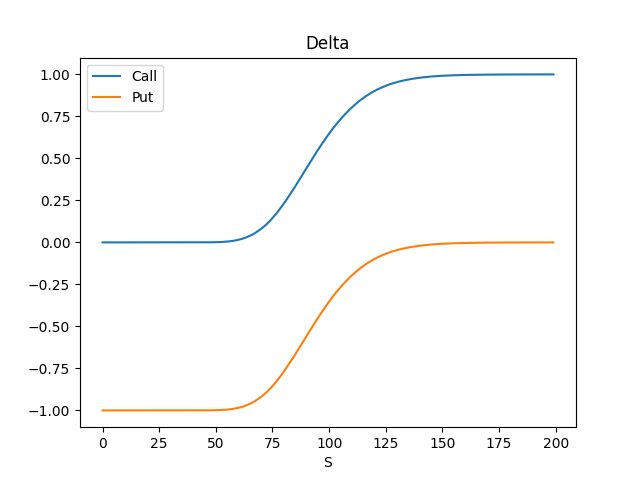

In [4]:
plt.plot(s[:-1], delta_call, label="Call")
plt.plot(s[:-1], delta_put, label="Put")

plt.xlabel("S")
plt.title("Delta")
plt.legend()

**Interpretación:** Al subir el precio del activo, delta de la call va de cerca de 0 a cerca de 1: la call responde cada vez más a ese cambio. Delta de la put va de cerca de -1 a 0: la put pierde valor cuando sube el activo, pero cada vez menos.

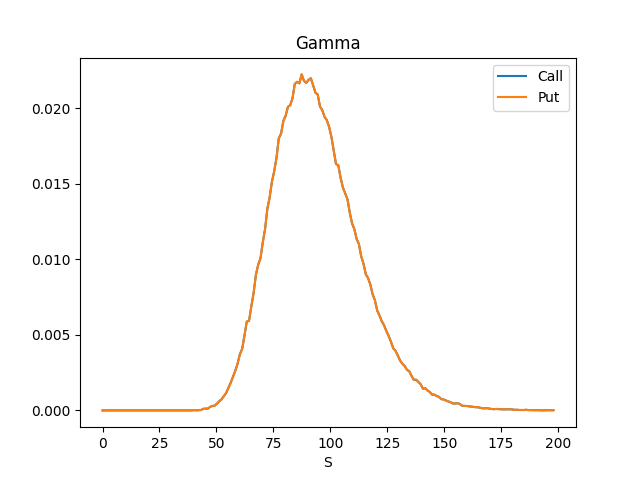

In [6]:
plt.plot(s[:-2], gamma_call, label="Call")
plt.plot(s[:-2], gamma_put, label="Put")

plt.xlabel("S")
plt.title("Gamma")
plt.legend()

**Interpretación:** Gamma es casi igual para call y put. Sube cerca del strike porque allí un pequeño movimiento del activo cambia mucho la delta; lejos del strike se acerca a cero.

# VEGA

In [ ]:
n_grid  = 200
n_paths = 200_000
k, r, s, T = 100, 0.05, 100, 1

vol = np.linspace(0, 2, n_grid)
h=vol[1] - vol[0]
def precio_call(sigma):
    ST = s * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    payoff_call= np.maximum(ST - k, 0)
    return np.exp(-r*T) * payoff_call.mean()
precios_call_vega= np.array([precio_call(sigma) for sigma in vol])

def precio_put(sigma):
    ST = s * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    payoff_call= np.maximum(k - ST, 0)
    return np.exp(-r*T) * payoff_call.mean()
precios_put_vega= np.array([precio_put(sigma) for sigma in vol])

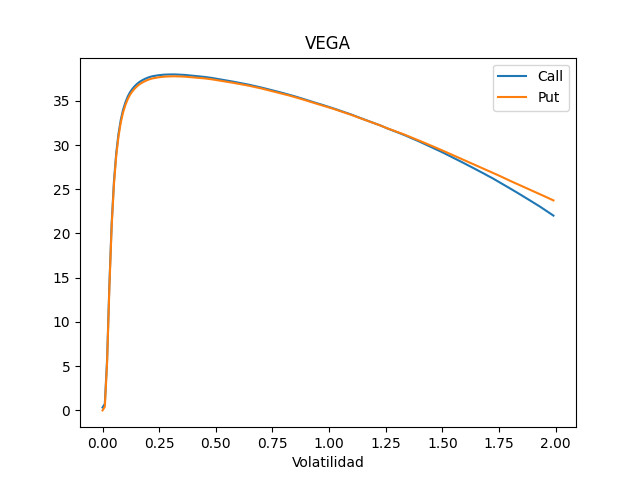

In [10]:
vega_call= np.diff(precios_call_vega) / h
vega_put= np.diff(precios_put_vega) / h 
plt.plot(vol[:-1],vega_call, label="Call")
plt.plot(vol[:-1],vega_put, label="Put")
plt.title("VEGA")
plt.xlabel("Volatilidad")
plt.legend()

**Interpretación:** Vega es positiva y parecida para call y put: más volatilidad suele aumentar el valor de ambas. Con estos parámetros, la sensibilidad crece al principio y luego disminuye cuando la volatilidad ya es muy alta.

# THETA

In [ ]:
n_grid = 200
k, r, s, vol = 100, 0.05, 100, 0.2

T = np.linspace(0.01, 2, n_grid)
h = T[1] - T[0]

def precio_call(t):
    ST = s * np.exp((r - 0.5*vol**2)*t + vol*np.sqrt(t)*Z)
    payoff_call = np.maximum(ST - k, 0)
    return np.exp(-r*t) * payoff_call.mean()

precios_call_theta = np.array([precio_call(t) for t in T])

def precio_put(t):
    ST = s * np.exp((r - 0.5*vol**2)*t + vol*np.sqrt(t)*Z)
    payoff_put = np.maximum(k - ST, 0)
    return np.exp(-r*t) * payoff_put.mean()

precios_put_theta = np.array([precio_put(t) for t in T])

# Theta mide el paso del tiempo: al pasar el tiempo, T disminuye.
theta_call = -np.diff(precios_call_theta) / h
theta_put = -np.diff(precios_put_theta) / h


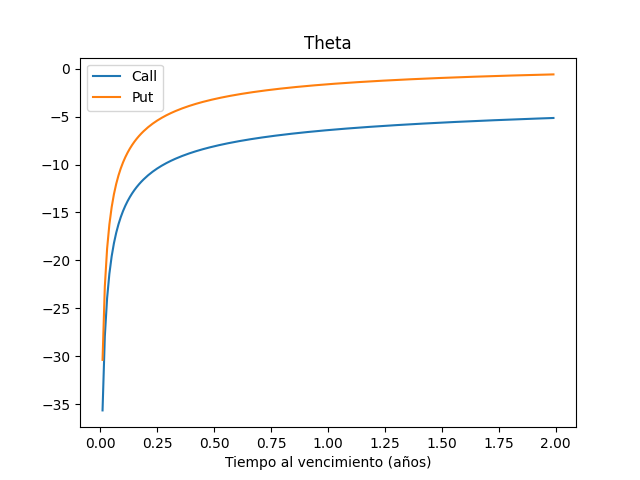

In [14]:
plt.plot(T[:-1], theta_call, label="Call")
plt.plot(T[:-1], theta_put, label="Put")
plt.title("Theta")
plt.xlabel("Tiempo al vencimiento (años)")
plt.legend()


**Interpretación:** Theta indica qué ocurre cuando pasa el tiempo y falta menos para vencer. Cerca del strike es negativa para call y put: ambas pierden valor temporal. La pérdida por día es más rápida cuando el vencimiento está cerca.

# RHO

In [ ]:
n_grid = 200
k, s, vol, T = 100, 100, 0.2, 1

r = np.linspace(0, 0.15, n_grid)
h = r[1] - r[0]

def precio_call(tasa):
    ST = s * np.exp((tasa - 0.5*vol**2)*T + vol*np.sqrt(T)*Z)
    payoff_call = np.maximum(ST - k, 0)
    return np.exp(-tasa*T) * payoff_call.mean()

precios_call_rho = np.array([precio_call(tasa) for tasa in r])

def precio_put(tasa):
    ST = s * np.exp((tasa - 0.5*vol**2)*T + vol*np.sqrt(T)*Z)
    payoff_put = np.maximum(k - ST, 0)
    return np.exp(-tasa*T) * payoff_put.mean()

precios_put_rho = np.array([precio_put(tasa) for tasa in r])

rho_call = np.diff(precios_call_rho) / h
rho_put = np.diff(precios_put_rho) / h


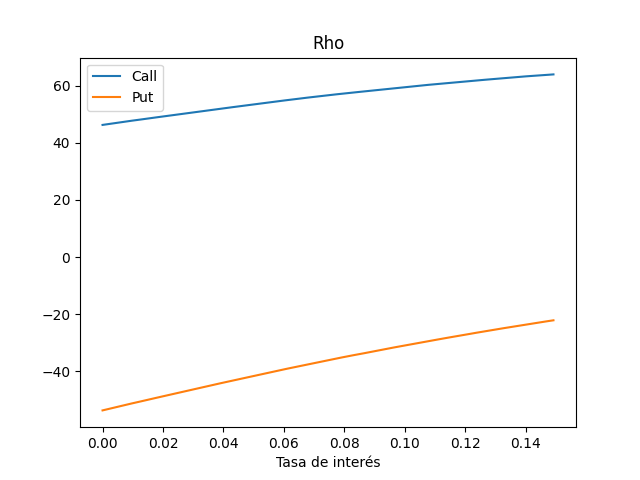

In [18]:
plt.plot(r[:-1], rho_call, label="Call")
plt.plot(r[:-1], rho_put, label="Put")
plt.title("Rho")
plt.xlabel("Tasa de interés")
plt.legend()


**Interpretación:** Rho de la call es positiva: al subir la tasa, la call gana valor. Rho de la put es negativa: la put pierde valor. Esto ocurre porque una tasa mayor reduce el valor presente del strike que se pagaría o recibiría al ejercer.